# Predicting Successfulness in 1-vs-1 Actions

This notebook aims to show how the model hyperparameters were trained, what the final models were, and how they performed.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.metrics import accuracy_score, recall_score, precision_score, roc_auc_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
import lightgbm

## Loading in the data

In [2]:
features = pd.read_pickle("data/features.pickle")
features.loc[features["outcome"]==-1, "outcome"] = 0

X = features.drop("outcome", axis=1).copy()
y = features["outcome"].copy().astype("category")
print("1vs1 action outcome counts:\n", y.value_counts())
# print("\nDescription of features:\n", X.describe())

1vs1 action outcome counts:
 outcome
0.0    378
1.0    356
Name: count, dtype: int64


In [3]:
# create validation set for hyperparameter tuning and a test_train set to obtain the performance of
# the model using a 5-fold stratified cross validation
random_state = 24

X_train_test, X_val, y_train_test, y_val = train_test_split(X, y, test_size=0.2, random_state=random_state, stratify=y)

print(X_train_test.shape, X_val.shape)
print(y_train_test.shape, y_val.shape)

(587, 24) (147, 24)
(587,) (147,)


## Creating necessary functions to make it easier to find the optimal hyperparameters

In [4]:
def run_random_cv(X, y, model, params, n_iter, random_state, scorer="accuracy"):
    """
    Simple function to run a random search using a 5-fold cross validation.
    This function can be used to get an initial best set of hyperparameters which can later
    be optimized with using grid search.

    Args:
        X: np.array: all features.
        y: np.array: all labels.
        model: estimator object: sklearn-like estimator
        params: dict: dict with parameters as key and a list of possible values as values.
        n_iter: int: number of iterations to search for the best performing model.
        random_state: int: random state of the randomized search.
        scorer (optional): sklearn-like scorer on which to rate the models. Defaults to "accuracy".
        
        
    Returns:
        estimator object: best performing model in the random search
    """
    search = RandomizedSearchCV(estimator=model, param_distributions=params, cv=5, n_iter = n_iter, verbose=1, error_score=0., random_state=random_state, n_jobs=-1, scoring=scorer)
    search.fit(X, y)
    tuned_model = search.best_estimator_
    return tuned_model

def run_grid_search_cv(X, y, model, params, scorer=accuracy_score):
    """
    Simple function to run a grid search using a 5-fold cross validation.
    This function can be used to get an initial best set of hyperparameters which can later.

    Args:
        X: np.array: all features.
        y: np.array: all labels.
        model: estimator object: sklearn-like estimator
        params: dict: dict with parameters as key and a list of possible values as values.
        scorer (optional): sklearn-like scorer on which to rate the models. Defaults to accuracy_scorer.
    Returns:
        estimator object: best performing model in the grid search
    """
    search = GridSearchCV(estimator=model, param_grid=params, cv=5, verbose=1, error_score=0., n_jobs=-1, scoring="accuracy")
    search.fit(X, y)
    best_model = search.best_estimator_
    return best_model

In [5]:
def quadspace(start, end, num_points, float_allowed=True):
    """
    Generate a list of values spaced quadratically between start and end.
    
    Args:
        start: float: The starting value.
        end: float: The ending value.
        num_points: int: The number of points in the list.
        float_allowed: bool: Whether floats are allowed in the output list.
            If False, all values are changed to int's. Defaults to True.

    Returns:
        A list of values spaced quadratically between start and end.
    """
    x = np.linspace(0, 1, num_points)
    quadratic_values = start + (end - start) * x**2
    if not float_allowed:
        quadratic_values = [round(val) for val in quadratic_values]
        quadratic_values = list(set(quadratic_values))
    return quadratic_values

## Find the optimal hyperparameters of the models

In total, 5 classifiers are trained:
1. Logistic Regression
2. Random Forrest
3. Ada Boost
4. Gradient Boost
5. Light Gradient Boost Machine

For the more complex models, a random search over the hyper parameters is conducted to get a initial selection, a second grid search, based on the hyperparameters of the random search, is conducted to find the final best hyperparameters for the model. For the smaller models, just running the grid search will be sufficient. For the logistic regression a standard scaler is used since it is a distance based model, for the tree-based models no scaling is needed.

### Logistic Regression

In [6]:
lr_model = LogisticRegression(random_state=random_state, warm_start=False, verbose=0, multi_class="ovr", max_iter=10000, fit_intercept=True, dual=False)
scaler = StandardScaler()
scaler.fit(X_val)
X_val_scaled = scaler.transform(X_val)
X_train_test_scaled = scaler.transform(X_train_test)

penalty_solver_combinations = [
    {
        'penalty': ['l2'], 
        'solver': ['lbfgs', 'newton-cg', 'newton-cholesky', 'sag', "saga", "liblinear"], 
        'C': quadspace(0.0001, 10000, 50),
        "class_weight":[None, "balanced"], 
        "n_jobs":[1], 
    },
    {
        'penalty': ['l1'], 
        'solver': ["liblinear", "saga"], 
        'C': quadspace(0.0001, 10000, 50),
        "class_weight":[None, "balanced"], 
        "n_jobs":[1], 
    },
    {
        'penalty': ["elasticnet"], 
        'solver': ["saga"], 
        'C': quadspace(0.0001, 10000, 50),
        "class_weight":[None, "balanced"], 
        "n_jobs":[-1], 
        "l1_ratio":quadspace(0.01, 0.99, 50)
    },   
]

best_lr_model = run_grid_search_cv(X_val_scaled, y_val, lr_model, penalty_solver_combinations)
print(best_lr_model.get_params())

Fitting 5 folds for each of 5800 candidates, totalling 29000 fits
{'C': 0.0001, 'class_weight': 'balanced', 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 10000, 'multi_class': 'ovr', 'n_jobs': 1, 'penalty': 'l2', 'random_state': 24, 'solver': 'saga', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}


### Random Forest

In [7]:
rf_model = RandomForestClassifier(random_state=random_state, warm_start=False, verbose=0, n_jobs=-1, bootstrap=True, max_leaf_nodes=None)

param_dist = {
    "n_estimators": quadspace(50, 500, 50, float_allowed=False),  
    "criterion": ["gini", "entropy"],
    "max_depth": [None] + list(range(1, 20)),
    "min_weight_fraction_leaf": quadspace(0.0, 0.4, 50),
    "max_features": ["sqrt", "log2", None],
    "min_impurity_decrease": quadspace(0.0, 0.4, 50),
    "oob_score": [True, False],
    "class_weight": [None, "balanced"],
    "ccp_alpha": quadspace(0.0, 0.4, 50),
    "max_samples": [None] + quadspace(1, 50, 50, float_allowed=False)
}

tuned_rf_model = run_random_cv(X_val, y_val, rf_model, param_dist, 10000, random_state)
print(tuned_rf_model.get_params())

Fitting 5 folds for each of 10000 candidates, totalling 50000 fits
{'bootstrap': True, 'ccp_alpha': 0.05397750937109537, 'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 14, 'max_features': None, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.00599750104123282, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.008163265306122448, 'n_estimators': 51, 'n_jobs': -1, 'oob_score': True, 'random_state': 24, 'verbose': 0, 'warm_start': False}


In [8]:
rf_model = RandomForestClassifier(random_state=random_state, warm_start=False, verbose=0, n_jobs=-1, bootstrap=True, max_leaf_nodes=None)

params = {
    'ccp_alpha': quadspace(0.005, 0.5, 4), 
    'class_weight': ["balanced"], 
    'criterion': ['entropy'], 
    'max_depth': [16, 14, 15], 
    'max_features': [None], 
    'min_impurity_decrease': quadspace(0.0005, 0.05, 4), 
    'min_weight_fraction_leaf': quadspace(0.0008, 0.08, 4), 
    'n_estimators': [40, 50, 60], 
    'oob_score': [True], 
}

best_rf_model = run_grid_search_cv(X_val, y_val, rf_model, params)
print(best_rf_model.get_params())

Fitting 5 folds for each of 576 candidates, totalling 2880 fits
{'bootstrap': True, 'ccp_alpha': 0.005, 'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 16, 'max_features': None, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.05, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.009600000000000001, 'n_estimators': 40, 'n_jobs': -1, 'oob_score': True, 'random_state': 24, 'verbose': 0, 'warm_start': False}


### Ada Boost 

In [9]:
import warnings
warnings.simplefilter("ignore")

ada_model = AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=random_state, class_weight="balanced"), random_state=random_state)

params = {
    'estimator__max_depth': [round(x) for x in range(1, 11)] ,
    'estimator__criterion': ["gini", "entropy", "log_loss"],
    'estimator__max_features': [None, "sqrt", "log2"],
    'estimator__ccp_alpha': quadspace(0.0, 0.4, 50),
    'n_estimators':quadspace(50, 500, 50, float_allowed=False),
    'learning_rate':quadspace(0.001, 10, 50),
    'algorithm': ["SAMME", "SAMME.R"],
}
tuned_ada_model = run_random_cv(X_val, y_val, ada_model, params, n_iter=10000, random_state=random_state)
print(tuned_ada_model.get_params())

Fitting 5 folds for each of 10000 candidates, totalling 50000 fits
{'algorithm': 'SAMME.R', 'base_estimator': 'deprecated', 'estimator__ccp_alpha': 0.028154935443565173, 'estimator__class_weight': 'balanced', 'estimator__criterion': 'entropy', 'estimator__max_depth': 10, 'estimator__max_features': None, 'estimator__max_leaf_nodes': None, 'estimator__min_impurity_decrease': 0.0, 'estimator__min_samples_leaf': 1, 'estimator__min_samples_split': 2, 'estimator__min_weight_fraction_leaf': 0.0, 'estimator__random_state': 24, 'estimator__splitter': 'best', 'estimator': DecisionTreeClassifier(ccp_alpha=0.028154935443565173, class_weight='balanced',
                       criterion='entropy', max_depth=10, random_state=24), 'learning_rate': 1.0671157850895456, 'n_estimators': 242, 'random_state': 24}


In [10]:
ada_model = AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=random_state, class_weight="balanced"), random_state=random_state)

params = {
    'estimator__max_depth': [8, 9, 10] ,
    'estimator__min_samples_leaf': [16, 17, 18],
    'estimator__criterion': ["entropy"],
    'estimator__max_features': [None],
    'estimator__ccp_alpha': quadspace(0.01, 0.05, 4),
    'n_estimators': [200, 240, 280],
    'learning_rate': quadspace(0.9, 1.4, 4),
    'algorithm': ["SAMME.R"],
}
best_ada_model = run_grid_search_cv(X_val, y_val, ada_model, params)
print(best_ada_model.get_params())

Fitting 5 folds for each of 432 candidates, totalling 2160 fits
{'algorithm': 'SAMME.R', 'base_estimator': 'deprecated', 'estimator__ccp_alpha': 0.01, 'estimator__class_weight': 'balanced', 'estimator__criterion': 'entropy', 'estimator__max_depth': 8, 'estimator__max_features': None, 'estimator__max_leaf_nodes': None, 'estimator__min_impurity_decrease': 0.0, 'estimator__min_samples_leaf': 16, 'estimator__min_samples_split': 2, 'estimator__min_weight_fraction_leaf': 0.0, 'estimator__random_state': 24, 'estimator__splitter': 'best', 'estimator': DecisionTreeClassifier(ccp_alpha=0.01, class_weight='balanced',
                       criterion='entropy', max_depth=8, min_samples_leaf=16,
                       random_state=24), 'learning_rate': 1.1222222222222222, 'n_estimators': 200, 'random_state': 24}


### Gradient Boosting

In [11]:
gb_model = GradientBoostingClassifier(random_state=random_state)

params = {
    "loss": ["log_loss"],
    "learning_rate": quadspace(0.001, 10, 50),
    "n_estimators": quadspace(50, 500, 50, float_allowed=False),
    "subsample": quadspace(0.01, 0.95, 50),
    "criterion": ["friedman_mse", "squared_error"],
    "min_samples_split": quadspace(0.01, 0.95, 50),
    "min_samples_leaf": quadspace(0.01, 0.95, 50),
    "max_depth": [round(x) for x in range(1, 11)],
    "min_impurity_decrease": quadspace(0.01, 100, 50),
    "max_features": ["sqrt", "log2"],
}

tuned_gb_model = run_random_cv(X_val, y_val, gb_model, params, n_iter=10000, random_state=random_state)
print(tuned_gb_model.get_params())

Fitting 5 folds for each of 10000 candidates, totalling 50000 fits
{'ccp_alpha': 0.0, 'criterion': 'squared_error', 'init': None, 'learning_rate': 0.2050612244897959, 'loss': 'log_loss', 'max_depth': 5, 'max_features': 'log2', 'max_leaf_nodes': None, 'min_impurity_decrease': 0.01, 'min_samples_leaf': 0.04171178675551853, 'min_samples_split': 0.1666014160766347, 'min_weight_fraction_leaf': 0.0, 'n_estimators': 57, 'n_iter_no_change': None, 'random_state': 24, 'subsample': 0.235506039150354, 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}


In [12]:
gb_model = GradientBoostingClassifier(random_state=random_state)

params = {
    "loss": ["log_loss"],
    "learning_rate": quadspace(0.1, 0.3, 4),
    "n_estimators": [45, 57, 73],
    "subsample": quadspace(0.15, 0.3, 4),
    "criterion": ["squared_error"],
    "min_samples_split": quadspace(0.1, 0.3, 4),
    "min_samples_leaf": quadspace(0.03, 0.05, 4),
    "max_depth": [4, 5, 6],
    "min_impurity_decrease": quadspace(0.005, 0.015, 3),
    "max_features": ["log2"],
}

best_gb_model = run_grid_search_cv(X_val, y_val, gb_model, params)
print(best_gb_model.get_params())

Fitting 5 folds for each of 6912 candidates, totalling 34560 fits
{'ccp_alpha': 0.0, 'criterion': 'squared_error', 'init': None, 'learning_rate': 0.12222222222222223, 'loss': 'log_loss', 'max_depth': 5, 'max_features': 'log2', 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0075, 'min_samples_leaf': 0.03, 'min_samples_split': 0.1, 'min_weight_fraction_leaf': 0.0, 'n_estimators': 57, 'n_iter_no_change': None, 'random_state': 24, 'subsample': 0.3, 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}


### Light Gradient Boosting

In [13]:
lgb_model = lightgbm.LGBMClassifier(random_state=random_state, n_jobs=-1, verbose=-100, importance_type="split")

params = {
        "boosting_type": ["gbdt", "dart", "rf"],
        "num_leaves": quadspace(4, 120, 50, float_allowed=False),
        "max_depth": [-1] + quadspace(1, 50, 50, float_allowed=False),
        "learning_rate": quadspace(0.001, 10, 50),
        "n_estimators": quadspace(50, 500, 50, float_allowed=False),
        "subsample_for_bin": quadspace(50000, 5000000, 50, float_allowed=False),
        "objective": ["binary"], # binary classification
        "class_weight": ["balanced", None], 
        "min_split_gain": quadspace(0.001, 100, 50),
        "min_child_weight": quadspace(0.001, 100, 50),
        "reg_alpha": quadspace(0.0, 0.99, 10), # L1 regularization term on weights
        "reg_lambda": quadspace(0.0, 0.99, 10), # L2 regularization term on weights
        "feature_fraction": quadspace(0.3, 0.99, 10),
        "bagging_fraction": quadspace(0.1, 0.99, 10),
    }
tuned_lgb_model = run_random_cv(X_val, y_val, lgb_model, params, n_iter=10000, random_state=random_state)
print(tuned_lgb_model.get_params())

Fitting 5 folds for each of 10000 candidates, totalling 50000 fits
{'boosting_type': 'dart', 'class_weight': None, 'colsample_bytree': 1.0, 'importance_type': 'split', 'learning_rate': 0.33832569762598913, 'max_depth': 5, 'min_child_samples': 20, 'min_child_weight': 0.04264889629321115, 'min_split_gain': 0.001, 'n_estimators': 65, 'n_jobs': -1, 'num_leaves': 13, 'objective': 'binary', 'random_state': 24, 'reg_alpha': 0.19555555555555554, 'reg_lambda': 0.99, 'subsample': 1.0, 'subsample_for_bin': 3686735, 'subsample_freq': 0, 'verbose': -100, 'feature_fraction': 0.3340740740740741, 'bagging_fraction': 0.37469135802469145}


In [14]:
lgb_model = lightgbm.LGBMClassifier(random_state=random_state, n_jobs=-1, verbose=-100, importance_type="split")

params = {
        "boosting_type": ["dart"],
        "num_leaves": [13],
        "max_depth": [5],
        "learning_rate": [0.3, 0.33, 0.35],
        "n_estimators": [60, 65, 70],
        "subsample_for_bin": [3686735],
        "objective": ["binary"], # binary classification
        "class_weight": [None], 
        "min_split_gain": [0.001],
        "min_child_weight": [0.04, 0.042, 0.044],
        "reg_alpha": [0.15, 0.2, 0.25], # L1 regularization term on weights
        "reg_lambda": [1.0], # L2 regularization term on weights
        "feature_fraction": [0.3, 0.33, 0.35],
        "bagging_fraction":[0.35, 0.37],
    }

best_lgb_model = run_grid_search_cv(X_val, y_val, lgb_model, params)
print(best_lgb_model.get_params())

Fitting 5 folds for each of 486 candidates, totalling 2430 fits
{'boosting_type': 'dart', 'class_weight': None, 'colsample_bytree': 1.0, 'importance_type': 'split', 'learning_rate': 0.3, 'max_depth': 5, 'min_child_samples': 20, 'min_child_weight': 0.04, 'min_split_gain': 0.001, 'n_estimators': 70, 'n_jobs': -1, 'num_leaves': 13, 'objective': 'binary', 'random_state': 24, 'reg_alpha': 0.2, 'reg_lambda': 1.0, 'subsample': 1.0, 'subsample_for_bin': 3686735, 'subsample_freq': 0, 'verbose': -100, 'bagging_fraction': 0.35, 'feature_fraction': 0.33}


## Obtaining model results

The function below is used to find the 5-fold stratified cross validation results on the performance of each model. It also returns the (permuation) feature importances to analyse which features are most important in the classifiers.

In [15]:
def obtain_results(model, X_train_test, y_train_test, random_state, verbose=True,):
    """
    Function to obtain the stratified 5 fold cross validation results from the models

    Args:
        model: estimator object: sklearn-like estimator.
        X_train_test: pd.DataFrame: the features of the train/test set
        y_train_test: pd.Series: the labels form the corresponding features of the train/test/set
        random_state: int: random state for the stratified kfold.
        verbose: bool (optional): whether to print the result in the terminal. Defaults to True

    Returns:
        Tuple[pd.DataFrame, list, list]: The performance over the five folds {accuracy, precision
            recall, auc, f1}, a list with the feature importances for every fold, and a list with the 
            permutation feature importances for every fold.
    """

    feature_importance_list = []
    scores = {"accuracy": [], "recall": [], "precision": [], "auc": [], "f1": []}
    feature_importances = []
    permuation_importances_list  = []

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
    for train_index, test_index in skf.split(X_train_test, y_train_test):
        X_train_fold, X_test_fold = X_train_test.iloc[train_index], X_train_test.iloc[test_index]
        y_train_fold, y_test_fold = y_train_test.iloc[train_index], y_train_test.iloc[test_index]

        model.fit(X_train_fold, y_train_fold)
        y_pred_fold = model.predict(X_test_fold)

        # Calculate performance for this fold
        scores["accuracy"].append(accuracy_score(y_test_fold, y_pred_fold))
        scores["precision"].append(precision_score(y_test_fold, y_pred_fold))
        scores["recall"].append(recall_score(y_test_fold, y_pred_fold))
        scores["auc"].append(roc_auc_score(y_test_fold, y_pred_fold))
        scores["f1"].append(f1_score(y_test_fold, y_pred_fold))

        # Get feature importances and store them for this fold
        if isinstance(model, DummyClassifier):
            continue
        permutation_importances = permutation_importance(
        model, X_test_fold, y_test_fold, n_repeats=50, random_state=random_state
        )
        permuation_importances_list.append(pd.Series(permutation_importances.importances_mean, index=features.columns[:-1]))

        if isinstance(model, LogisticRegression):
            feature_importances.append(pd.Series(model.coef_[0], index=features.columns[:-1]))
        else:
            feature_importances.append(pd.Series(model.feature_importances_, index=features.columns[:-1]))

    scores = pd.DataFrame(scores)
    if verbose:
        print(model)
        print(scores.describe())
    
    return scores, feature_importances, permuation_importances_list


In [16]:
X_train_test_scaled_df = pd.DataFrame(index=X_train_test.index, columns=X_train_test.columns, data=X_train_test_scaled)
lr_scores, lr_feature_importances, lr_permutation_feature_importances = obtain_results(best_lr_model, X_train_test_scaled_df, y_train_test, random_state)

LogisticRegression(C=0.0001, class_weight='balanced', max_iter=10000,
                   multi_class='ovr', n_jobs=1, random_state=24, solver='saga')
       accuracy    recall  precision       auc        f1
count  5.000000  5.000000   5.000000  5.000000  5.000000
mean   0.579357  0.585965   0.566445  0.579676  0.574710
std    0.074269  0.082847   0.078502  0.073938  0.074197
min    0.504274  0.473684   0.490909  0.503509  0.482143
25%    0.533898  0.561404   0.516129  0.534800  0.537815
50%    0.542373  0.578947   0.522388  0.544722  0.564516
75%    0.641026  0.614035   0.647059  0.639474  0.611111
max    0.675214  0.701754   0.655738  0.675877  0.677966


In [17]:
rf_scores, rf_feature_importances, rf_permutation_feature_importances = obtain_results(best_rf_model, X_train_test, y_train_test, random_state)

RandomForestClassifier(ccp_alpha=0.005, class_weight='balanced',
                       criterion='entropy', max_depth=16, max_features=None,
                       min_impurity_decrease=0.05,
                       min_weight_fraction_leaf=0.009600000000000001,
                       n_estimators=40, n_jobs=-1, oob_score=True,
                       random_state=24)
       accuracy    recall  precision       auc        f1
count  5.000000  5.000000   5.000000  5.000000  5.000000
mean   0.558699  0.540351   0.550776  0.558318  0.536902
std    0.040645  0.136120   0.051047  0.040585  0.071204
min    0.512821  0.403509   0.500000  0.510088  0.446602
25%    0.529915  0.403509   0.513158  0.533772  0.489362
50%    0.550847  0.543860   0.534483  0.550618  0.539130
75%    0.589744  0.666667   0.584615  0.585088  0.586466
max    0.610169  0.684211   0.621622  0.612022  0.622951


In [18]:
ada_scores, ada_feature_importances, ada_permutation_feature_importances = obtain_results(best_ada_model, X_train_test, y_train_test, random_state)

AdaBoostClassifier(estimator=DecisionTreeClassifier(ccp_alpha=0.01,
                                                    class_weight='balanced',
                                                    criterion='entropy',
                                                    max_depth=8,
                                                    min_samples_leaf=16,
                                                    random_state=24),
                   learning_rate=1.1222222222222222, n_estimators=200,
                   random_state=24)
       accuracy    recall  precision       auc        f1
count  5.000000  5.000000   5.000000  5.000000  5.000000
mean   0.669492  0.652632   0.659291  0.669130  0.651154
std    0.055607  0.137806   0.038617  0.057382  0.091245
min    0.598291  0.421053   0.631579  0.593860  0.505263
25%    0.649573  0.666667   0.633333  0.650000  0.649573
50%    0.669492  0.684211   0.650000  0.669974  0.666667
75%    0.677966  0.701754   0.655738  0.678746  0.677966
max    0.75

In [19]:
gb_scores, gb_feature_importances, gb_permutation_feature_importances = obtain_results(best_gb_model, X_train_test, y_train_test, random_state)


GradientBoostingClassifier(criterion='squared_error',
                           learning_rate=0.12222222222222223, max_depth=5,
                           max_features='log2', min_impurity_decrease=0.0075,
                           min_samples_leaf=0.03, min_samples_split=0.1,
                           n_estimators=57, random_state=24, subsample=0.3)
       accuracy    recall  precision       auc        f1
count  5.000000  5.000000   5.000000  5.000000  5.000000
mean   0.652484  0.628070   0.647860  0.651931  0.636300
std    0.058212  0.076873   0.065782  0.058108  0.064492
min    0.606838  0.508772   0.593750  0.604386  0.557692
25%    0.615385  0.596491   0.607143  0.614912  0.601770
50%    0.618644  0.666667   0.617021  0.620219  0.628099
75%    0.677966  0.666667   0.666667  0.677596  0.666667
max    0.743590  0.701754   0.754717  0.742544  0.727273


In [20]:
lgb_scores, lgb_feature_importances, lgb_permutation_feature_importances = obtain_results(tuned_lgb_model, X_train_test, y_train_test, random_state)


LGBMClassifier(bagging_fraction=0.37469135802469145, boosting_type='dart',
               feature_fraction=0.3340740740740741,
               learning_rate=0.33832569762598913, max_depth=5,
               min_child_weight=0.04264889629321115, min_split_gain=0.001,
               n_estimators=65, n_jobs=-1, num_leaves=13, objective='binary',
               random_state=24, reg_alpha=0.19555555555555554, reg_lambda=0.99,
               subsample_for_bin=3686735, verbose=-100)
       accuracy    recall  precision       auc        f1
count  5.000000  5.000000   5.000000  5.000000  5.000000
mean   0.686499  0.649123   0.684528  0.685572  0.664763
std    0.071004  0.116373   0.066858  0.072070  0.089997
min    0.589744  0.491228   0.595745  0.587281  0.538462
25%    0.666667  0.596491   0.666667  0.664912  0.635514
50%    0.669492  0.631579   0.680000  0.668248  0.648649
75%    0.728814  0.754386   0.698413  0.730227  0.733333
max    0.777778  0.771930   0.781818  0.777193  0.767857


In [21]:
dummy_model = DummyClassifier(random_state=random_state)
dummy_scores, _, _ = obtain_results(dummy_model, X_train_test, y_train_test, random_state)


DummyClassifier(random_state=24)
       accuracy  recall  precision  auc   f1
count  5.000000     5.0        5.0  5.0  5.0
mean   0.514472     0.0        0.0  0.5  0.0
std    0.002261     0.0        0.0  0.0  0.0
min    0.512821     0.0        0.0  0.5  0.0
25%    0.512821     0.0        0.0  0.5  0.0
50%    0.512821     0.0        0.0  0.5  0.0
75%    0.516949     0.0        0.0  0.5  0.0
max    0.516949     0.0        0.0  0.5  0.0


### Feature importances

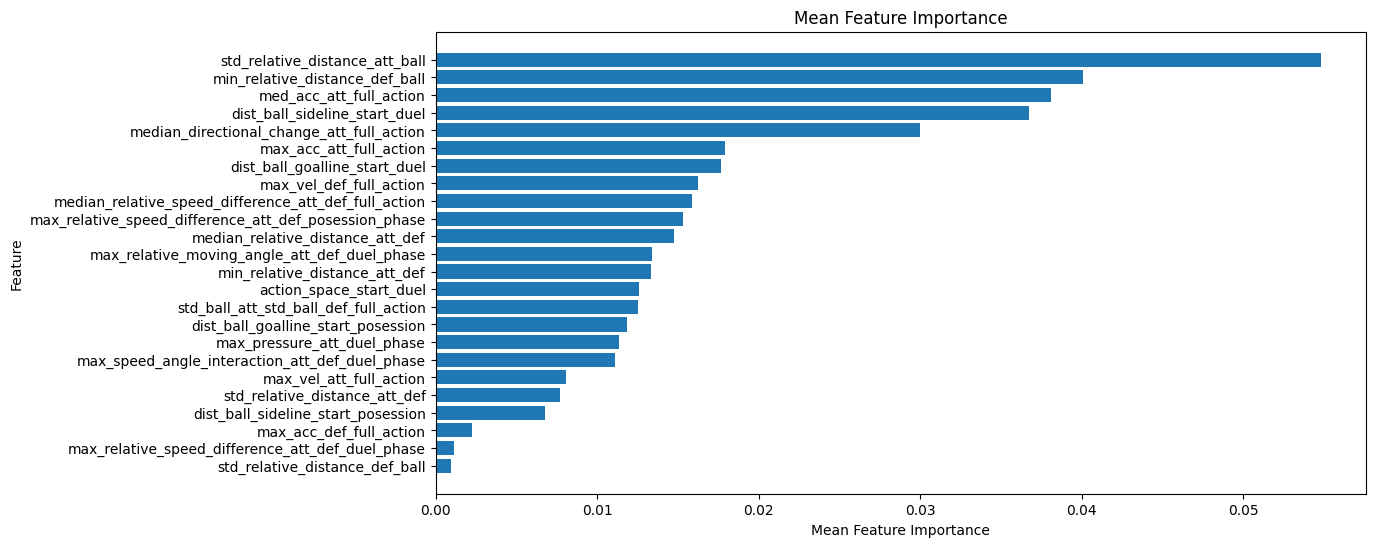

In [22]:
feature_importances_mean = pd.concat(lgb_permutation_feature_importances, axis=1).T.mean()
feature_importances_mean = feature_importances_mean.sort_values(ascending=False)

plt.figure(figsize=(12, 6))
plt.barh(range(len(feature_importances_mean)), feature_importances_mean, align='center')
plt.yticks(range(len(feature_importances_mean)), feature_importances_mean.index)
plt.xlabel('Mean Feature Importance')
plt.ylabel('Feature')
plt.title('Mean Feature Importance')
plt.gca().invert_yaxis()  # Invert the y-axis to show the most important features at the top
plt.show()

In [23]:
round(feature_importances_mean * 100, 2)

std_relative_distance_att_ball                           5.48
min_relative_distance_def_ball                           4.01
med_acc_att_full_action                                  3.81
dist_ball_sideline_start_duel                            3.67
median_directional_change_att_full_action                3.00
max_acc_att_full_action                                  1.80
dist_ball_goalline_start_duel                            1.77
max_vel_def_full_action                                  1.62
median_relative_speed_difference_att_def_full_action     1.59
max_relative_speed_difference_att_def_posession_phase    1.53
median_relative_distance_att_def                         1.48
max_relative_moving_angle_att_def_duel_phase             1.34
min_relative_distance_att_def                            1.33
action_space_start_duel                                  1.26
std_ball_att_std_ball_def_full_action                    1.25
dist_ball_goalline_start_posession                       1.18
max_pres